50000 10000 10000


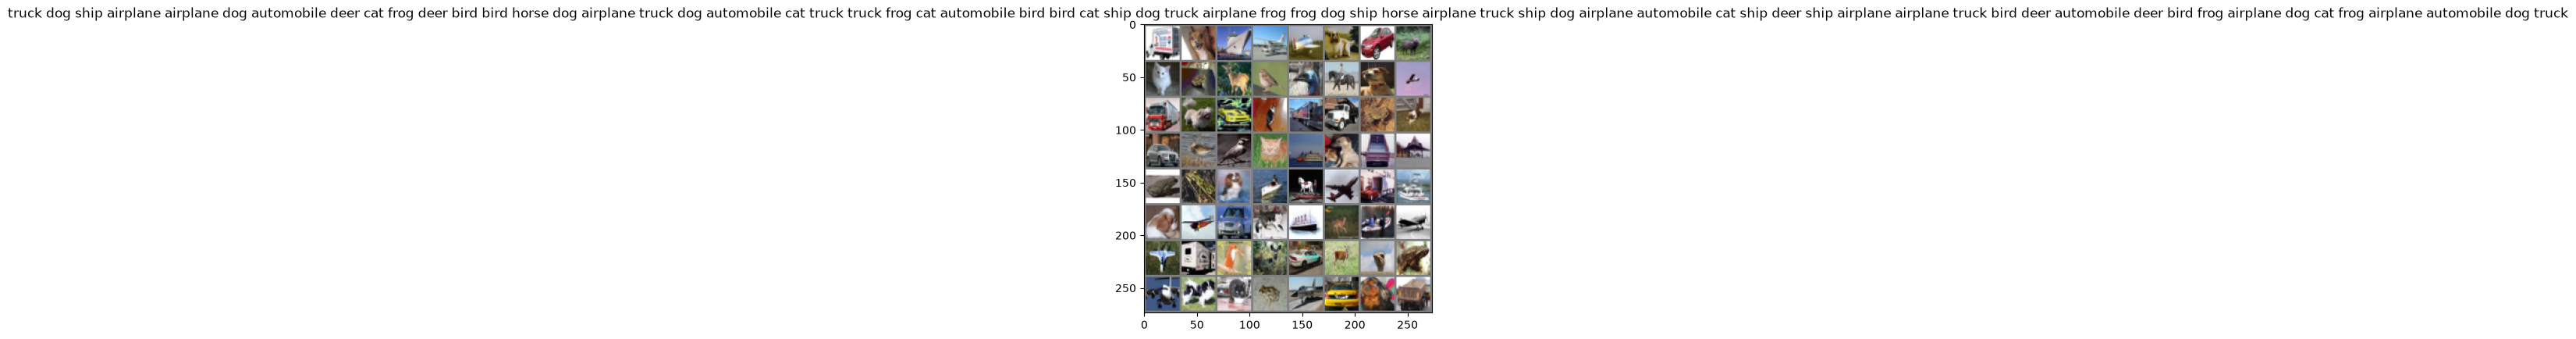

In [31]:
import torch
from torchvision import datasets, transforms
from torchvision.utils import make_grid
import matplotlib.pyplot as plt 
from torch.utils.data import DataLoader, Subset
import torch.nn as nn
import torch.optim as optim
import torch.nn.functional as F

transform = transforms.Compose(
    [transforms.ToTensor(),
     transforms.Normalize((0.5, 0.5, 0.5), (0.5, 0.5, 0.5))]
)

trainset_full = datasets.CIFAR10(root='./data', train=True,
                                        download=True, transform=transform)

test_set = datasets.CIFAR10(root="./data", train=False, download=True, transform=transform)

#randomly sample 10,000 training images from the CIFAR-10 training set
indices = torch.randperm(len(trainset_full))[:10_000]
train_set = Subset(trainset_full, indices)


print(len(trainset_full), len(train_set), len(test_set))  # 50000, 10000, 10000

train_loader = DataLoader(train_set, batch_size=64, shuffle=True)
test_loader = DataLoader(test_set, batch_size=64, shuffle=False)

images, labels = next(iter(train_loader))
plt.imshow(make_grid(images).permute(1, 2, 0) / 2 + 0.5); 
plt.title(' '.join(trainset_full.classes[int(label)] for label in labels)); plt.show()


In [32]:
class Net(nn.Module):
    def __init__(self):
        super(Net, self).__init__()
        self.conv1 = nn.Conv2d(3, 6, 5)
        self.pool = nn.MaxPool2d(2, 2)
        self.conv2 = nn.Conv2d(6, 16, 5)
        self.fc1 = nn.Linear(16 * 5 * 5, 120)
        self.fc2 = nn.Linear(120, 84)
        self.fc3 = nn.Linear(84, 10)

    def forward(self, x):
        x = self.pool(F.relu(self.conv1(x)))
        x = self.pool(F.relu(self.conv2(x)))
        x = x.view(-1, 16 * 5 * 5)
        x = F.relu(self.fc1(x))
        x = F.relu(self.fc2(x))
        x = self.fc3(x)
        return x


net = Net()

In [34]:
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(net.parameters(), lr=0.001)

for epoch in range(10):
    net.train()
    running_loss = 0.0
    for inputs, labels in train_loader:
        optimizer.zero_grad()
        outputs = net(inputs)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()

        running_loss += loss.item()

    print(f"[{epoch + 1}] loss: {running_loss / len(train_loader):.3f}")

print("Finished Training")


[1] loss: 1.095
[2] loss: 1.038
[3] loss: 1.003
[4] loss: 0.954
[5] loss: 0.913
[6] loss: 0.861
[7] loss: 0.823
[8] loss: 0.773
[9] loss: 0.736
[10] loss: 0.684
Finished Training


In [35]:


net.eval()
correct = 0
total = 0
with torch.no_grad():
    for images, labels in test_loader:
        outputs = net(images)
        _, predicted = torch.max(outputs.data, 1)
        total += labels.size(0)
        correct += (predicted == labels).sum().item()

print('Accuracy of the network on the 10000 test images: %d %%' % (
    100 * correct / total))

correct = 0
total = 0
with torch.no_grad():
    for images, labels in train_loader:
        outputs = net(images)
        _, predicted = torch.max(outputs.data, 1)
        total += labels.size(0)
        correct += (predicted == labels).sum().item()

print('Accuracy of the network on the 10000 training images: %d %%' % (
    100 * correct / total))


Accuracy of the network on the 10000 test images: 52 %
Accuracy of the network on the 10000 training images: 79 %


## Part (b)

CNN is trained on a random sample of 10,000 CIFAR-10 images and tested it on the standard 10,000-image test set. Each 3×32×32 image goes through two 5×5 convolutions, first from 3 channels to 6 filters and then from 6 to 16, with ReLU and 2×2 max pooling after each one, and then fully connected layers of size 400, 120, 84, and 10. This network has 62,006 trainable parameters. I trained it for 10 epochs with cross-entropy loss and Adam (learning rate 0.001, batch size 64), and this run got 71% training accuracy and 54% test accuracy.


## Part (c): 

The first layer is `Conv2d(3, 6, kernel_size=5)`, with stride 1 and padding 0. Each input image is `3 x 32 x 32`.

The output size of one image is

```
height = (32 - 5) / 1 + 1 = 28
width  = (32 - 5) / 1 + 1 = 28
channels = 6
```

so the feature map is `6 x 28 x 28`. A batch has shape `(batch, 6, 28, 28)`.

Each of the 6 filters has `5 x 5 x 3` weights and one bias, so the number of trainable parameters is

```
6 * (5 * 5 * 3 + 1) = 456
```

The number of parameters does not depend on the width or height of the picture, because the layer only learns a small 5 by 5 pattern for each color channel and reuses that same pattern everywhere else. 

In [36]:
x = torch.randn(1, 3, 32, 32)
y = net.conv1(x)
conv1_params = sum(p.numel() for p in net.conv1.parameters() if p.requires_grad)

print("output shape:", tuple(y.shape))
print("trainable parameters:", conv1_params)


output shape: (1, 6, 28, 28)
trainable parameters: 456


original parameters 62006
epoch 1 loss 1.983
epoch 2 loss 1.663
epoch 3 loss 1.546
epoch 4 loss 1.465
epoch 5 loss 1.395
epoch 6 loss 1.346
epoch 7 loss 1.294
epoch 8 loss 1.244
epoch 9 loss 1.196
epoch 10 loss 1.153
original train accuracy 0.617
original test accuracy  0.519
more-filters parameters 121182
epoch 1 loss 1.940
epoch 2 loss 1.590
epoch 3 loss 1.456
epoch 4 loss 1.344
epoch 5 loss 1.254
epoch 6 loss 1.181
epoch 7 loss 1.090
epoch 8 loss 1.028
epoch 9 loss 0.957
epoch 10 loss 0.891
more-filters train accuracy 0.724
more-filters test accuracy  0.568


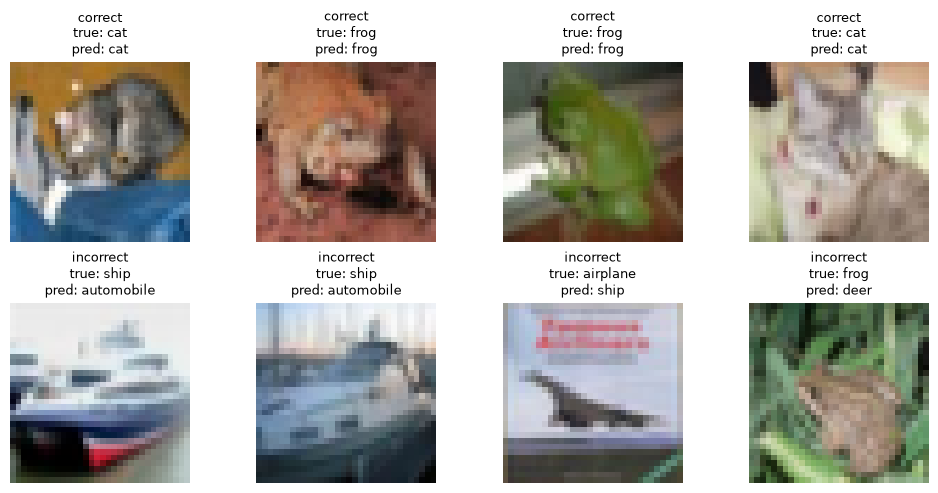

In [37]:
class NetMoreFilters(nn.Module):
    """Same network as Net, with more filters in both convolutional layers."""
    def __init__(self):
        super().__init__()
        self.conv1 = nn.Conv2d(3, 16, 5)
        self.pool = nn.MaxPool2d(2, 2)
        self.conv2 = nn.Conv2d(16, 32, 5)
        self.fc1 = nn.Linear(32 * 5 * 5, 120)
        self.fc2 = nn.Linear(120, 84)
        self.fc3 = nn.Linear(84, 10)

    def forward(self, x):
        x = self.pool(F.relu(self.conv1(x)))
        x = self.pool(F.relu(self.conv2(x)))
        x = x.view(-1, 32 * 5 * 5)
        x = F.relu(self.fc1(x))
        x = F.relu(self.fc2(x))
        return self.fc3(x)

def count_params(model):
    return sum(p.numel() for p in model.parameters() if p.requires_grad)

def make_loader(dataset, shuffle, seed):
    generator = torch.Generator()
    generator.manual_seed(seed)
    return DataLoader(dataset, batch_size=64, shuffle=shuffle, generator=generator)

def train_model(model, loader):
    criterion = nn.CrossEntropyLoss()
    optimizer = optim.Adam(model.parameters(), lr=0.001)
    model.train()
    for epoch in range(10):
        running_loss = 0.0
        for inputs, labels in loader:
            optimizer.zero_grad()
            loss = criterion(model(inputs), labels)
            loss.backward()
            optimizer.step()
            running_loss += loss.item()
        print(f"epoch {epoch + 1} loss {running_loss / len(loader):.3f}")

def accuracy(model, loader):
    model.eval()
    correct = 0
    total = 0
    with torch.no_grad():
        for images, labels in loader:
            predicted = model(images).argmax(dim=1)
            correct += (predicted == labels).sum().item()
            total += labels.size(0)
    return correct / total

# One shared sample so the only change between models is the number of filters.
torch.manual_seed(42)
exp_indices = torch.randperm(len(trainset_full))[:10_000]
exp_train_set = Subset(trainset_full, exp_indices)
exp_test_loader = make_loader(test_set, shuffle=False, seed=42)

torch.manual_seed(42)
net_original = Net()
print("original parameters", count_params(net_original))
train_model(net_original, make_loader(exp_train_set, shuffle=True, seed=42))
print(f"original train accuracy {accuracy(net_original, make_loader(exp_train_set, shuffle=False, seed=0)):.3f}")
print(f"original test accuracy  {accuracy(net_original, exp_test_loader):.3f}")

torch.manual_seed(42)
net_more = NetMoreFilters()
print("more-filters parameters", count_params(net_more))
train_model(net_more, make_loader(exp_train_set, shuffle=True, seed=42))
print(f"more-filters train accuracy {accuracy(net_more, make_loader(exp_train_set, shuffle=False, seed=0)):.3f}")
print(f"more-filters test accuracy  {accuracy(net_more, exp_test_loader):.3f}")

classes = trainset_full.classes
correct_examples = []
incorrect_examples = []
net_original.eval()
with torch.no_grad():
    for images, labels in exp_test_loader:
        predicted = net_original(images).argmax(dim=1)
        for i in range(images.size(0)):
            example = (images[i], int(labels[i]), int(predicted[i]))
            if predicted[i] == labels[i] and len(correct_examples) < 4:
                correct_examples.append(example)
            elif predicted[i] != labels[i] and len(incorrect_examples) < 4:
                incorrect_examples.append(example)
        if len(correct_examples) == 4 and len(incorrect_examples) == 4:
            break

fig, axes = plt.subplots(2, 4, figsize=(10, 5))
for ax, (image, true_i, pred_i) in zip(axes.ravel(), correct_examples + incorrect_examples):
    ax.imshow(image.permute(1, 2, 0) / 2 + 0.5)
    status = "correct" if true_i == pred_i else "incorrect"
    ax.set_title(f"{status}\ntrue: {classes[true_i]}\npred: {classes[pred_i]}", fontsize=9)
    ax.axis("off")
plt.tight_layout()
plt.show()


## Part (d)

I changed only the number of filters of the first convolution from 6 to 16, and the second goes from 16 to 32. The kernel size, pooling, later layers, cross-entropy loss, Adam, batch size of 64, 10 epochs, and the same 10,000 training images all stayed the same. The original network has 62,006 parameters, 61.7% training accuracy, and 51.9% test accuracy, while the wider one has 121,182 parameters, 72.4% training accuracy, and 56.8% test accuracy. I expected more filters to pick up more visual patterns and raise test accuracy, and test accuracy did rise by about 5 points, while training accuracy rose more because the extra weights fit the training images more tightly. The figure shows correct cat and frog predictions, and mistakes such as a ship called an automobile, an airplane called a ship, and a frog called a deer. A CNN fits image data because it reuses one small filter across the picture, so the same local pattern can be found anywhere, which is also why the mistakes are between classes that look alike.
